# Split a document into ~200-word chunks and keep their bounding boxes

This recipe uses `Document.to_chunks()` (PyMuPDF >= 2.0) to split a document
into retrieval-ready chunks of about 200 words, and keeps the bounding box of
every chunk so you can show, highlight or verify where each chunk came from.

In [1]:
%pip install -q pymupdf


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import random

import pymupdf

print("PyMuPDF", pymupdf.__version__)

PyMuPDF 2.1


## 1. Make a sample PDF

To keep the recipe self-contained, we generate a small test document:
3 Letter-size pages, each with a 16pt heading and six paragraphs of 10pt
filler text (40–90 random words each).

This is an easy case for the chunker: no tables, columns, headers or footers,
and clear gaps between paragraphs. To use your own file, skip this cell and
set `SOURCE_PDF` to its path.

In [3]:
SOURCE_PDF = "sample.pdf"

random.seed(1)  # same "random" text on every run
WORDS = (
    "alpha beta gamma delta river stone light market signal "
    "method data figure result value system process"
).split()

sample = pymupdf.open()  # new, empty PDF
for page_no in range(3):
    page = sample.new_page()  # Letter size: 612 x 792 points
    y = 72                    # start 1 inch from the top

    # Heading: to_chunks() uses headings as section starts
    page.insert_text((72, y), f"Section {page_no + 1}", fontsize=16)
    y += 30

    # Six paragraphs, each in its own text box
    for _ in range(6):
        text = " ".join(random.choice(WORDS) for _ in range(random.randint(40, 90))) + "."
        box = pymupdf.Rect(72, y, 540, y + 110)
        spare = page.insert_textbox(box, text, fontsize=10)  # unused height in the box
        y += 110 + spare + 12  # move down past the text, plus a gap

sample.save(SOURCE_PDF)
sample.close()
print(f"Wrote {SOURCE_PDF}")

Wrote sample.pdf


## 2. Count words instead of tokens

`to_chunks()` sizes chunks in *tokens*. Its `tokenizer` parameter accepts any
callable `text -> int`, so a word counter makes `max_tokens` mean "max words".

In [4]:
MAX_WORDS = 200


def count_words(text: str) -> int:
    """One 'token' per whitespace-separated word."""
    return len(text.split())

## 3. Chunk the document

Chunk boundaries follow the layout (headings, paragraphs, page breaks), so
chunks are *up to* about 200 words rather than exactly 200. An indivisible
block, such as a preserved table, can be larger.

Each chunk's `metadata.bboxes` holds `(page, x0, y0, x1, y1)` tuples:
a 1-based page number and coordinates in PDF points (1/72 inch), measured
from the top-left corner of the unrotated page.

In [5]:
def chunk_document(path: str, max_words: int = MAX_WORDS) -> list[dict]:
    """Return a list of chunk records: text, word count, pages and bboxes."""
    with pymupdf.open(path) as doc:
        chunked = doc.to_chunks(
            max_tokens=max_words,
            min_tokens=max_words // 4,     # merge tiny fragments into neighbours
            tokenizer=count_words,         # "tokens" are now words
            header_footer_mode="exclude",  # keep running headers/footers out
        )

    records = []
    for chunk in chunked:
        md = chunk.metadata
        records.append(
            {
                "id": chunk.id,                # "c0", "c1", ...
                "text": chunk.text,            # Markdown text
                "word_count": count_words(chunk.text),
                "page_start": md.page_start,   # 1-based
                "page_end": md.page_end,       # 1-based
                "section_path": list(md.section_path),
                "bboxes": [
                    {"page": p, "rect": [x0, y0, x1, y1]}
                    for (p, x0, y0, x1, y1) in md.bboxes
                ],
            }
        )
    return records


chunks = chunk_document(SOURCE_PDF)
print(f"{len(chunks)} chunks")

rapidocr_api using backend: rapidocr

=== Document parser messages ===
Using RapidOCR for OCR processing.
7 chunks


## 4. Inspect the chunks

A chunk can cover several layout boxes, and occasionally more than one page.
`page_union_boxes()` merges a chunk's boxes into one rectangle per page,
which is convenient for highlighting.

In [6]:
def page_union_boxes(record: dict) -> dict[int, list[float]]:
    """One enclosing rectangle per page for a chunk."""
    out: dict[int, pymupdf.Rect] = {}
    for b in record["bboxes"]:
        r = pymupdf.Rect(b["rect"])
        out[b["page"]] = out[b["page"]] | r if b["page"] in out else r
    return {page: [round(v, 1) for v in rect] for page, rect in out.items()}


for c in chunks:
    pages = (
        f"p{c['page_start']}"
        if c["page_start"] == c["page_end"]
        else f"p{c['page_start']}-{c['page_end']}"
    )
    print(f"{c['id']:>4}  {pages:<7} {c['word_count']:>4} words  "
          f"{len(c['bboxes'])} box(es)  {page_union_boxes(c)}")

  c0  p1       196 words  1 box(es)  {1: [72.0, 60.1, 540.0, 508.4]}
  c1  p1        92 words  1 box(es)  {1: [72.0, 600.1, 539.4, 813.2]}
  c2  p2       159 words  1 box(es)  {2: [72.0, 60.1, 540.0, 349.1]}
  c3  p2       169 words  2 box(es)  {2: [72.0, 412.3, 537.8, 785.7]}
  c4  p3       172 words  1 box(es)  {3: [72.0, 60.1, 540.0, 333.4]}
  c5  p3       156 words  1 box(es)  {3: [72.0, 398.6, 539.9, 627.5]}
  c6  p3        57 words  1 box(es)  {3: [72.0, 719.2, 522.8, 773.0]}


## 5. Save the chunks as JSON

Plain lists and dicts, ready for a vector store or a front end.

In [7]:
with open("chunks.json", "w", encoding="utf-8") as f:
    json.dump(chunks, f, indent=2, ensure_ascii=False)
print("Wrote chunks.json")

Wrote chunks.json


## 6. Check the boxes visually

Outline every chunk's boxes in a *copy* of the PDF (never overwrite the
original) and render page 1 to a PNG. Remember PyMuPDF page indexes are
0-based, while the chunk metadata uses 1-based page numbers.

Wrote chunks-outlined.pdf and chunks-page1.png


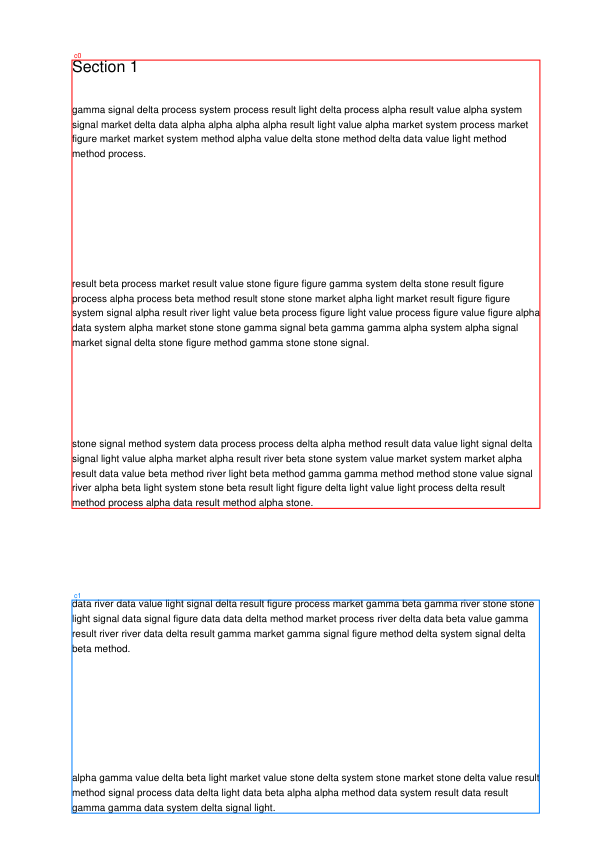

In [8]:
def draw_chunk_boxes(path: str, records: list[dict], out_path: str) -> None:
    """Draw each chunk's boxes and id onto a copy of the document."""
    colors = [(1, 0, 0), (0, 0.5, 1), (0, 0.7, 0), (1, 0.5, 0)]
    with pymupdf.open(path) as doc:
        for i, rec in enumerate(records):
            color = colors[i % len(colors)]
            for b in rec["bboxes"]:
                page = doc[b["page"] - 1]  # 1-based -> 0-based
                page.draw_rect(b["rect"], color=color, width=1)
                page.insert_text(
                    pymupdf.Rect(b["rect"]).tl + (2, -2),
                    rec["id"], fontsize=7, color=color,
                )
        doc.save(out_path)


draw_chunk_boxes(SOURCE_PDF, chunks, "chunks-outlined.pdf")

with pymupdf.open("chunks-outlined.pdf") as doc:
    doc[0].get_pixmap(dpi=72).save("chunks-page1.png")
print("Wrote chunks-outlined.pdf and chunks-page1.png")

# Show the rendered page inline
from IPython.display import Image, display
display(Image("chunks-page1.png"))

## 7. Try other sizes without re-parsing

`reassemble_chunks()` rebuilds the chunks from the units already parsed,
so you can compare chunk sizes quickly. The tokenizer from step 3 is kept.

In [9]:
with pymupdf.open(SOURCE_PDF) as doc:
    chunked = doc.to_chunks(max_tokens=MAX_WORDS, tokenizer=count_words)

for size in (100, 200, 300):
    resized = chunked.reassemble_chunks(max_tokens=size, min_tokens=size // 4)
    counts = [count_words(c.text) for c in resized]
    print(f"max {size:>3} words -> {len(resized)} chunks, largest {max(counts)} words")


=== Document parser messages ===
Using RapidOCR for OCR processing.
max 100 words -> 14 chunks, largest 92 words
max 200 words -> 7 chunks, largest 196 words
max 300 words -> 5 chunks, largest 288 words
